# Lab 2: Linear Systems

Ideas by Mike. Code by Claude. Text by both.

## Setup

Run the cell below as-is.

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import cbook

np.set_printoptions(precision=3, suppress=True)

### Question 1: Balancing a chemical equation

The original roadside breathalyzers worked by a colour change. Orange potassium dichromate reacts with the ethanol in a person's breath and turns into green chromium sulfate. The unbalanced reaction is

$$
x_1\,\mathrm{K_2Cr_2O_7} + x_2\,\mathrm{C_2H_5OH} + x_3\,\mathrm{H_2SO_4}
\;\to\;
x_4\,\mathrm{Cr_2(SO_4)_3} + x_5\,\mathrm{CH_3COOH} + x_6\,\mathrm{K_2SO_4} + x_7\,\mathrm{H_2O}
$$

Balancing it means finding coefficients so that each element appears the same number of times on both sides. For example, potassium (K) gives $2x_1 = 2x_6$, which we rewrite as $2x_1 - 2x_6 = 0$.

**(a)** Write the balance equation for each element as a row of a matrix `A`, so that the equations are $Ax = 0$. Use the rows K, Cr, O, C, H, S and the columns $x_1, \dots, x_7$.

In [ ]:
# TODO
A.shape

**(b)** There are 7 unknowns but only 6 equations, and $x = 0$ is not a useful answer. If $x$ balances the reaction, so does $2x$, so we are free to choose one coefficient. Add the equation $x_1 = 1$ as a new row to make a square system, then solve it with `np.linalg.solve`.

In [ ]:
# TODO
x

**(c)** Coefficients must be whole numbers. Multiply `x` by the smallest positive integer that makes every entry whole, and store the result in `x_whole`. The check below should print all zeros. Then write out the balanced equation.

In [ ]:
# TODO
print(x_whole)
print(A @ x_whole)

_Your answer here._

### Question 2: Piecewise polynomial interpolation

In calculus class last year, you were asked to draw a function meeting the following requirements:

- stationary points at $x=0$ and $x=2$
- a local maximum at $(0, 5)$
- a local minimum at $x = 1$
- a flat inflection point at $x = 2$
- a local maximum at $(3, 5)$
 
Here we find an exact formula for a function like this, on the interval $[0,5]$. We'll stitch together a few **cubics**. We want our function to be $C^1$ smooth, meaning its derivative is continuous.

**(a)** Write out the equations for some cubics. You can decide how many cubs and where the stitch points are.

e.g. 
- Cubic 1: $ax^3+bx^2+cx+d$ from $[0,1.5]$

_Your answer here._

**(b)** Write out all 6 equations and rearrange each one so the unknowns are on the left. The first is done for you:

$f_1(0.5) = f_2(0.5)$ gives $0.125c_1 + 0.25c_2 + 5 = 0.25c_3 + c_4$, which rearranges to $-0.125c_1 - 0.25c_2 + 0.25c_3 + c_4 = 5$.

_Your answer here._

**(c)** Write these equations as $Ac = b$ and solve for `c`.

In [ ]:
# TODO
c

**(d)** Run the cell below to plot your function. The dashed lines mark the joins. The curve should have no jumps or corners, and it should have all four features listed above.

In [ ]:
def f(x, c):
    return np.piecewise(x, [x <= 0.5, (x > 0.5) & (x <= 1.5), (x > 1.5) & (x <= 2.5), x > 2.5], [
        lambda x: c[0] * x**3 + c[1] * x**2 + 5,
        lambda x: c[2] * (x - 1)**2 + c[3],
        lambda x: c[4] * (x - 2)**3,
        lambda x: c[5] * (x - 3)**2 + 5,
    ])

xs = np.linspace(-0.25, 3.5, 500)
plt.plot(xs, f(xs, c), linewidth=2)
for join in [0.5, 1.5, 2.5]:
    plt.axvline(join, color="gray", linestyle="--", linewidth=1)
for mid, label in zip([0, 1, 2, 3], ["$f_1$", "$f_2$", "$f_3$", "$f_4$"]):
    plt.text(mid, 6.2, label, ha="center")
plt.ylim(-6, 7)
plt.xlabel("x")
plt.ylabel("f(x)")
plt.show()

### Question 3: Image filters as matrix multiplication

This question uses matrix multiplication, not solving.

A greyscale image is a 2D array of brightness values from 0 (black) to 1 (white). Here is one, at $64 \times 64$ pixels: computing pioneer Grace Hopper.

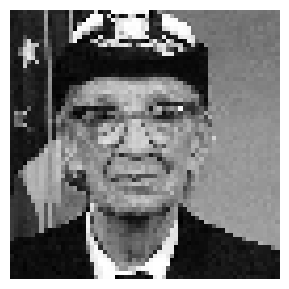

(64, 64)

In [3]:
with cbook.get_sample_data("grace_hopper.jpg") as file:
    photo = plt.imread(file)

img = photo[40:440:6, 90:490:6].mean(axis=2)[:64, :64] / 255

def show(*images, titles=None):
    fig, axes = plt.subplots(1, len(images), figsize=(3.5 * len(images), 3.5), squeeze=False)
    for i, (ax, image) in enumerate(zip(axes[0], images)):
        ax.imshow(image, cmap="gray")
        ax.axis("off")
        if titles:
            ax.set_title(titles[i])
    plt.show()

show(img)
img.shape

A **convolution** replaces each pixel with a weighted sum of itself and its neighbours. The weights are given by a small grid called a **kernel**. Here is a $7 \times 7$ blur kernel, shown as an image. It puts the most weight on the centre pixel and less on pixels further away, and its weights add up to 1.

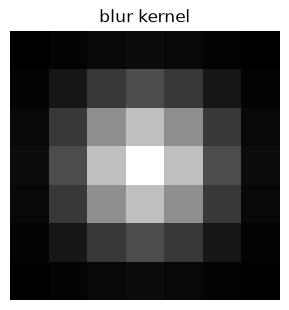

(7, 7)

In [4]:
weights = np.array([1, 6, 15, 20, 15, 6, 1]) / 64
blur = np.outer(weights, weights)

show(blur, titles=["blur kernel"])
blur.shape

To work with matrix multiplication, we lay an image out as one long vector. These functions do that, row by row, and undo it.

In [5]:
def flatten(img):
    return img.reshape(-1)

def unflatten(vector, h, w):
    return vector.reshape(h, w)

small = np.array([[1, 2, 3],
                  [4, 5, 6]])
print(flatten(small))
print(unflatten(flatten(small), 2, 3))

[1 2 3 4 5 6]
[[1 2 3]
 [4 5 6]]


To find one new pixel, place the kernel over that pixel on an otherwise blank image. `place_kernel` does this for us. Parts of the kernel that fall outside the image are cut off.

A weighted sum is a dot product, so the new pixel is the flattened placed kernel `@` the flattened image.

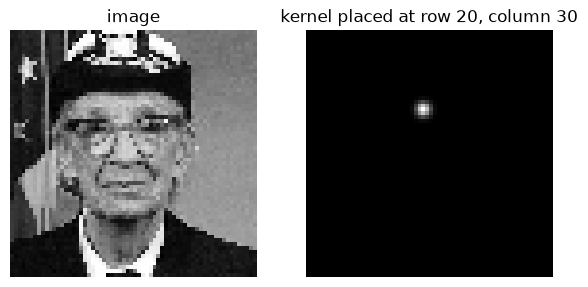

In [6]:
def place_kernel(kernel, r, c, h, w):
    k = kernel.shape[0] // 2
    canvas = np.zeros((h + 2 * k, w + 2 * k))
    canvas[r:r + 2 * k + 1, c:c + 2 * k + 1] = kernel
    return canvas[k:h + k, k:w + k]

h, w = img.shape
placed = place_kernel(blur, 20, 30, h, w)
show(img, placed, titles=["image", "kernel placed at row 20, column 30"])

**(a)** Use `flatten` and `@` to compute the new value of the pixel at row 20, column 30. Store it in `new_pixel`.

In [7]:
# TODO
print(img[20, 30], new_pixel)

NameError: name 'new_pixel' is not defined

Now do that for every pixel at once. If we stack the flattened placed kernels as the rows of a matrix $A$, with one row per pixel, then $A$ times the flattened image computes all of those dot products:

$$\text{new image} = \texttt{unflatten}(A \, @ \, \texttt{flatten}(\text{image}))$$

In [ ]:
def conv_matrix(kernel, h, w):
    return np.array([flatten(place_kernel(kernel, r, c, h, w))
                     for r in range(h) for c in range(w)])

**(b)** What is the shape of `A` for our $64 \times 64$ image? For a $7 \times 7$ kernel, what is the largest number of nonzero entries a row of `A` can have?

_Your answer here._

**(c)** Build `A` with `conv_matrix`. Then use `flatten`, `@` and `unflatten` to blur `img`, storing the result in `blurred`. The first line printed should be your `new_pixel` from (a), twice.

In [ ]:
# TODO
print(blurred[20, 30], new_pixel)
show(img, blurred, titles=["original", "blurred"])

**(d)** Here is the top-left corner of `A`, where white entries are zero. Why does a matrix for such a simple filter have stripes, and why are the stripes in groups?

In [ ]:
plt.imshow(A[:200, :200] == 0, cmap="gray")
plt.axhline(63.5, color="gray", linewidth=0.5)
plt.axvline(63.5, color="gray", linewidth=0.5)
plt.show()

_Your answer here._

**(e)** A different kernel gives a different filter, with the same code. Use `conv_matrix` to apply `edges`, which is near 0 wherever a pixel matches its neighbours. Store the result in `outlined`.

In [ ]:
edges = np.array([[-1, -1, -1],
                  [-1,  8, -1],
                  [-1, -1, -1]])

# TODO
show(img, np.clip(outlined, 0, 1), titles=["original", "edges"])

### Question 4 (Extending): Rotating a 3D point cloud

Below is a cloud of 1000 points in the shape of a letter F. `points` has shape `(3, 1000)`, so each **column** is one point $(x, y, z)$. The colours follow the points, so you can track where each part of the F goes.

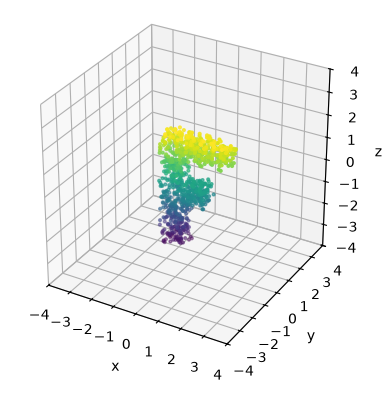

(3, 1000)

In [8]:
rng = np.random.default_rng(0)

def box(low, high, n):
    return rng.uniform(low, high, size=(n, 3))

points = np.vstack([box([0, 0, 0], [1, 1, 5], 550),
                    box([1, 0, 4], [3, 1, 5], 275),
                    box([1, 0, 2], [2, 1, 3], 175)]).T
points = points - points.mean(axis=1, keepdims=True)

def plot_clouds(*clouds, titles=None):
    fig = plt.figure(figsize=(4.5 * len(clouds), 4.5))
    for i, cloud in enumerate(clouds):
        ax = fig.add_subplot(1, len(clouds), i + 1, projection="3d")
        ax.scatter(*cloud, c=points[2], cmap="viridis", s=4)
        ax.set(xlim=(-4, 4), ylim=(-4, 4), zlim=(-4, 4), xlabel="x", ylabel="y", zlabel="z")
        ax.set_box_aspect((1, 1, 1))
        if titles:
            ax.set_title(titles[i])
    plt.show()

plot_clouds(points)
points.shape

These matrices rotate a point by an angle $\theta$ around the $z$-axis and around the $x$-axis:

$$
R_z = \begin{bmatrix} \cos\theta & -\sin\theta & 0 \\ \sin\theta & \cos\theta & 0 \\ 0 & 0 & 1 \end{bmatrix}
\qquad
R_x = \begin{bmatrix} 1 & 0 & 0 \\ 0 & \cos\theta & -\sin\theta \\ 0 & \sin\theta & \cos\theta \end{bmatrix}
$$

**(a)** Complete `rotate_z` and `rotate_x`, which take an angle in radians. Because each column of `points` is a point, `R @ points` rotates every point at once. Use this to rotate the cloud by 90 degrees around the $z$-axis, storing the result in `rotated_z`. `np.radians` converts degrees to radians.

In [ ]:
def rotate_z(theta):
    # TODO
    pass

def rotate_x(theta):
    # TODO
    pass

# TODO
plot_clouds(points, rotated_z, titles=["original", "rotated 90° around z"])

**(b)** Let `Rz = rotate_z(np.radians(90))` and `Rx = rotate_x(np.radians(90))`. Plot the cloud after rotating around $z$ first and then $x$, storing it in `z_then_x`, and after rotating around $x$ first and then $z$, storing it in `x_then_z`. Do you get the same result? What does this tell you about matrix multiplication?

In [ ]:
# TODO
plot_clouds(z_then_x, x_then_z, titles=["z, then x", "x, then z"])

_Your answer here._

**(c)** Now go backwards. Let `R = Rx @ Rz`. You are given `moved = R @ points`, and you want the original points back. This is a linear system, $Rx = \text{moved}$, and `np.linalg.solve` accepts a matrix on the right-hand side, solving for each column. Use it to compute `recovered`. Then compute `R.T @ moved` and compare the two. What does this tell you about the inverse of a rotation matrix?

In [ ]:
R = Rx @ Rz
moved = R @ points

# TODO
print(np.allclose(recovered, points))
plot_clouds(moved, recovered, titles=["moved", "recovered"])

_Your answer here._